In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/dataset-senti/Compressed/test_labels.pt
/kaggle/input/dataset-senti/Compressed/train_labels.pt
/kaggle/input/dataset-senti/Compressed/train_input_ids.pt
/kaggle/input/dataset-senti/Compressed/test_input_ids.pt
/kaggle/input/dataset-senti/Compressed/val_lengths.pt
/kaggle/input/dataset-senti/Compressed/val_input_ids.pt
/kaggle/input/dataset-senti/Compressed/train_lengths.pt
/kaggle/input/dataset-senti/Compressed/val_idx.npy
/kaggle/input/dataset-senti/Compressed/train_idx.npy
/kaggle/input/dataset-senti/Compressed/test_idx.npy
/kaggle/input/dataset-senti/Compressed/test_lengths.pt
/kaggle/input/dataset-senti/Compressed/val_labels.pt


In [15]:
import torch
import os
from torch.utils.data import Dataset, DataLoader
import numpy as np

In [16]:
torch.manual_seed(42)

In [17]:
# Set device (GPU if available, else CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [18]:
# Define paths to preprocessed data
DATA_DIR = "/kaggle/input/dataset-senti/Compressed"

In [19]:
# Load preprocessed tensors
train_input_ids = torch.load(os.path.join(DATA_DIR, "train_input_ids.pt"))
val_input_ids = torch.load(os.path.join(DATA_DIR, "val_input_ids.pt"))
test_input_ids = torch.load(os.path.join(DATA_DIR, "test_input_ids.pt"))

train_lengths = torch.load(os.path.join(DATA_DIR, "train_lengths.pt"))
val_lengths = torch.load(os.path.join(DATA_DIR, "val_lengths.pt"))
test_lengths = torch.load(os.path.join(DATA_DIR, "test_lengths.pt"))

train_labels = torch.load(os.path.join(DATA_DIR, "train_labels.pt"))
val_labels = torch.load(os.path.join(DATA_DIR, "val_labels.pt"))
test_labels = torch.load(os.path.join(DATA_DIR, "test_labels.pt"))

print(f"Loaded training samples: {len(train_labels)}")
print(f"Loaded validation samples: {len(val_labels)}")
print(f"Loaded test samples: {len(test_labels)}")

Loaded training samples: 1400000
Loaded validation samples: 300000
Loaded test samples: 300000


In [20]:
# Global training configuration
CONFIG = {
    "BATCH_SIZE": 128,
    "EPOCHS": 20,
    "LEARNING_RATE": 1e-3,
    "MAX_SEQ_LENGTH": 170,
    "DEVICE": DEVICE
}

print("Setup complete.")

Setup complete.


In [22]:
# Cell 2: Define PyTorch Dataset and DataLoader for biLSTM
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, input_ids, labels, lengths):
        self.input_ids = input_ids
        self.labels = labels
        self.lengths = lengths

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "label": self.labels[idx],
            "length": self.lengths[idx]
        }

# Create dataset instances
train_dataset = SentimentDataset(train_input_ids, train_labels, train_lengths)
val_dataset = SentimentDataset(val_input_ids, val_labels, val_lengths)
test_dataset = SentimentDataset(test_input_ids, test_labels, test_lengths)

# DataLoader creation
train_loader = DataLoader(train_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=True,pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=False, pin_memory=True)

In [23]:
# Print a sample batch to verify shapes and contents
sample_batch = next(iter(train_loader))
print("Sample batch keys:", sample_batch.keys())
print("input_ids shape:", sample_batch["input_ids"].shape)
print("labels shape:", sample_batch["label"].shape)
print("lengths shape:", sample_batch["length"].shape)

Sample batch keys: dict_keys(['input_ids', 'label', 'length'])
input_ids shape: torch.Size([128, 170])
labels shape: torch.Size([128])
lengths shape: torch.Size([128])


In [24]:
import torch
import torch.nn as nn

class BiLSTMSentimentClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        lstm_hidden_dim=64,
        dense_hidden_dim=64,
        dropout_rate=0.3,
        padding_idx=0
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=padding_idx
        )

        self.bilstm1 = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=lstm_hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.bilstm2 = nn.LSTM(
            input_size=lstm_hidden_dim * 2,
            hidden_size=lstm_hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout_rate)
        self.fc1 = nn.Linear(lstm_hidden_dim * 2, dense_hidden_dim)
        self.batchnorm = nn.BatchNorm1d(dense_hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(dense_hidden_dim, 1)

    def forward(self, input_ids, lengths):
        embedded = self.embedding(input_ids)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        out1, _ = self.bilstm1(packed)
        out1_unpacked, _ = nn.utils.rnn.pad_packed_sequence(out1, batch_first=True)

        packed = nn.utils.rnn.pack_padded_sequence(
            out1_unpacked, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden_n, _) = self.bilstm2(packed)

        # Concatenate last forward and backward hidden states
        hidden = torch.cat((hidden_n[-2], hidden_n[-1]), dim=1)  # (B, H*2)

        x = self.dropout(hidden)
        x = self.fc1(x)
        x = self.batchnorm(x)
        x = self.relu(x)
        x = self.dropout(x)
        logits = self.fc2(x)
        return logits


In [25]:
VOCAB_SIZE = 20000
EMBEDDING_DIM = 64
LSTM_HIDDEN_DIM = 64
DENSE_HIDDEN_DIM = 64
DROPOUT_RATE = 0.3
PAD_TOKEN_ID = 0  

In [26]:
model = BiLSTMSentimentClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    lstm_hidden_dim=LSTM_HIDDEN_DIM,
    dense_hidden_dim=DENSE_HIDDEN_DIM,
    dropout_rate=DROPOUT_RATE,
    padding_idx=PAD_TOKEN_ID
).to(CONFIG["DEVICE"])

print(model)

BiLSTMSentimentClassifier(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (bilstm1): LSTM(64, 64, batch_first=True, bidirectional=True)
  (bilstm2): LSTM(128, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (batchnorm): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [27]:
# Cell 4: Set up optimizer, loss function, and training utilities
# Explanation:
# - We use Adam optimizer, a common choice for NLP.
# - We use BCEWithLogitsLoss, which combines a sigmoid layer and the BCELoss in one for numerical stability.
# - We'll also define an accuracy metric for monitoring training/validation.

import torch.optim as optim

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)

# Loss function (for raw logits)
criterion = nn.BCEWithLogitsLoss()

# Move loss function to the correct device
criterion = criterion.to(CONFIG["DEVICE"])

# Accuracy metric
def binary_accuracy(preds, y):
    """
    Computes accuracy for binary predictions.
    preds: raw logits from the model
    y: ground truth labels (float tensor, 0 or 1)
    """
    # Apply sigmoid to get probabilities
    probs = torch.sigmoid(preds)
    # Convert probabilities to 0 or 1
    rounded = torch.round(probs)
    correct = (rounded == y).float()
    acc = correct.sum() / len(correct)
    return acc

print("Optimizer, loss function, and accuracy metric are set up.")

Optimizer, loss function, and accuracy metric are set up.


In [28]:
# Cell 5: Training and Validation Loop
# Explanation:
# - This cell defines the training and evaluation loops for the biLSTM model.
# - It uses pack_padded_sequence for variable-length batching, tracks loss and accuracy, and saves the best model.

import time

def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    epoch_loss = 0
    epoch_acc = 0
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        labels = batch["label"].to(device).float()
        lengths = batch["length"].to(device)
        optimizer.zero_grad()
        logits = model(input_ids, lengths).squeeze(1)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        acc = binary_accuracy(logits, labels)
        epoch_loss += loss.item() * len(labels)
        epoch_acc += acc.item() * len(labels)
    return epoch_loss / len(loader.dataset), epoch_acc / len(loader.dataset)

def eval_epoch(model, loader, criterion, device):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            labels = batch["label"].to(device).float()
            lengths = batch["length"].to(device)
            logits = model(input_ids, lengths).squeeze(1)
            loss = criterion(logits, labels)
            acc = binary_accuracy(logits, labels)
            epoch_loss += loss.item() * len(labels)
            epoch_acc += acc.item() * len(labels)
    return epoch_loss / len(loader.dataset), epoch_acc / len(loader.dataset)


In [29]:
NUM_EPOCHS = 15
PATIENCE = 3  # Early stopping patience

best_val_loss = float('inf')
epochs_no_improve = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(NUM_EPOCHS):
    start_time = time.time()
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, CONFIG["DEVICE"])
    val_loss, val_acc = eval_epoch(model, val_loader, criterion, CONFIG["DEVICE"])
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    elapsed = time.time() - start_time

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | "
          f"Time: {elapsed:.1f}s")

    # Early stopping logic
    if val_loss < best_val_loss - 1e-4:  # Minimum improvement threshold
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), "/kaggle/working/best_bilstm_model.pt")
        print("  (Best model saved)")
    else:
        epochs_no_improve += 1
        print(f"  (No improvement for {epochs_no_improve} epoch(s))")
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered after {epoch+1} epochs.")
            break

print("Training complete.")
# Save stats for later plotting
np.save("/kaggle/working/train_losses.npy", np.array(train_losses))
np.save("/kaggle/working/val_losses.npy", np.array(val_losses))
np.save("/kaggle/working/train_accs.npy", np.array(train_accs))
np.save("/kaggle/working/val_accs.npy", np.array(val_accs))

Epoch 1/15 | Train Loss: 0.2155 | Train Acc: 91.27% | Val Loss: 0.1641 | Val Acc: 93.70% | Time: 472.4s
  (Best model saved)
Epoch 2/15 | Train Loss: 0.1601 | Train Acc: 93.94% | Val Loss: 0.1514 | Val Acc: 94.19% | Time: 475.0s
  (Best model saved)
Epoch 3/15 | Train Loss: 0.1481 | Train Acc: 94.45% | Val Loss: 0.1437 | Val Acc: 94.56% | Time: 477.5s
  (Best model saved)
Epoch 4/15 | Train Loss: 0.1401 | Train Acc: 94.81% | Val Loss: 0.1396 | Val Acc: 94.75% | Time: 477.7s
  (Best model saved)
Epoch 5/15 | Train Loss: 0.1346 | Train Acc: 95.03% | Val Loss: 0.1374 | Val Acc: 94.83% | Time: 481.4s
  (Best model saved)
Epoch 6/15 | Train Loss: 0.1303 | Train Acc: 95.21% | Val Loss: 0.1368 | Val Acc: 94.90% | Time: 483.5s
  (Best model saved)
Epoch 7/15 | Train Loss: 0.1265 | Train Acc: 95.37% | Val Loss: 0.1369 | Val Acc: 94.80% | Time: 488.8s
  (No improvement for 1 epoch(s))
Epoch 8/15 | Train Loss: 0.1231 | Train Acc: 95.51% | Val Loss: 0.1352 | Val Acc: 94.97% | Time: 485.3s
  (Best 

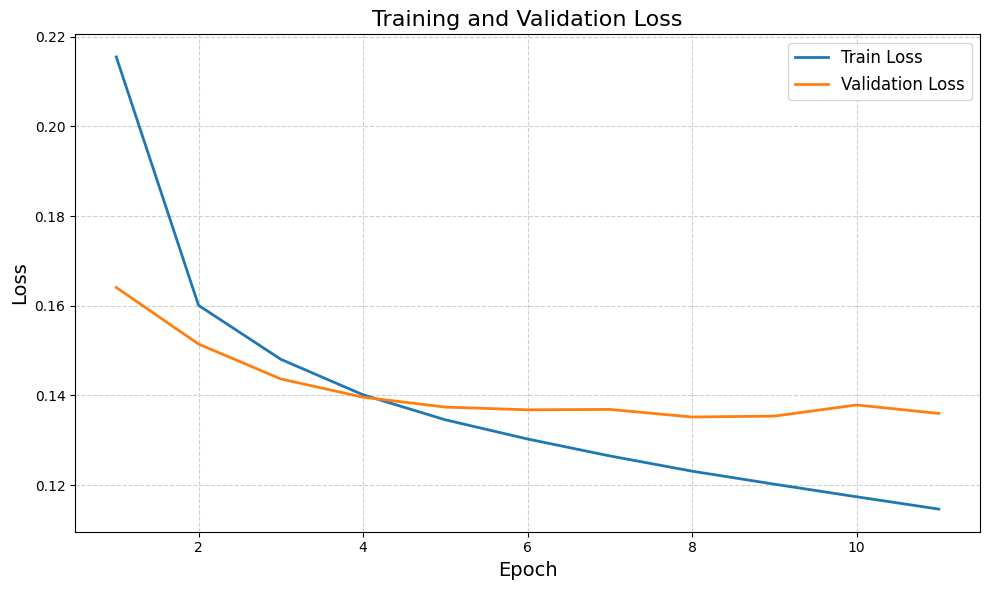

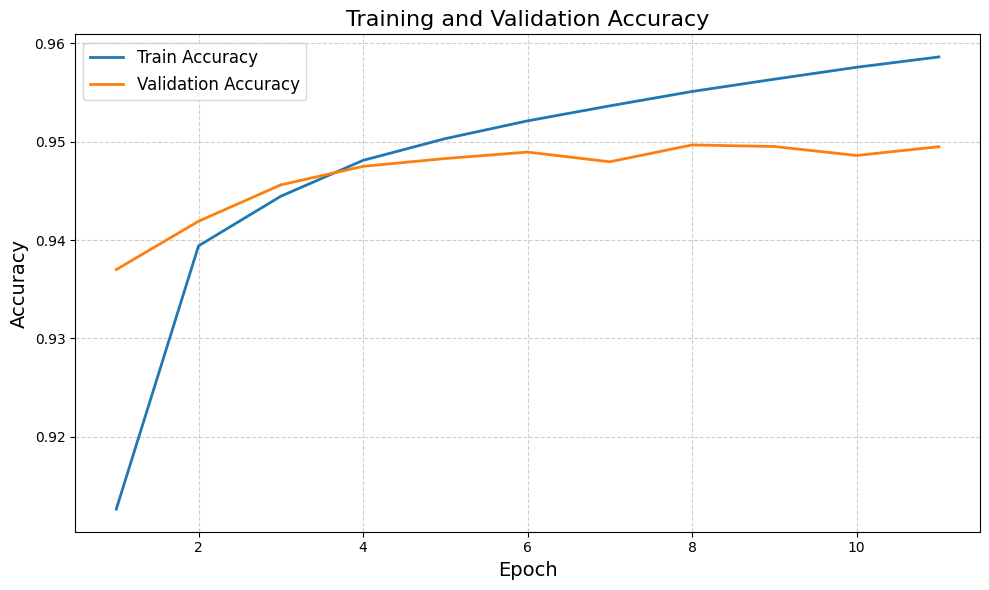

In [30]:
import os
import matplotlib.pyplot as plt
import numpy as np


# Create epochs array based on the number of epochs completed
epochs = np.arange(1, len(train_losses) + 1)

# Plot Loss
plt.figure(figsize=(10,6))
plt.plot(epochs, train_losses, label='Train Loss', linewidth=2)
plt.plot(epochs, val_losses, label='Validation Loss', linewidth=2)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Training and Validation Loss', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/kaggle/working/loss_plot.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot Accuracy
plt.figure(figsize=(10,6))
plt.plot(epochs, train_accs, label='Train Accuracy', linewidth=2)
plt.plot(epochs, val_accs, label='Validation Accuracy', linewidth=2)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.title('Training and Validation Accuracy', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/kaggle/working/accuracy_plot.png', dpi=300, bbox_inches='tight')
plt.show()


Test Accuracy: 95.02%


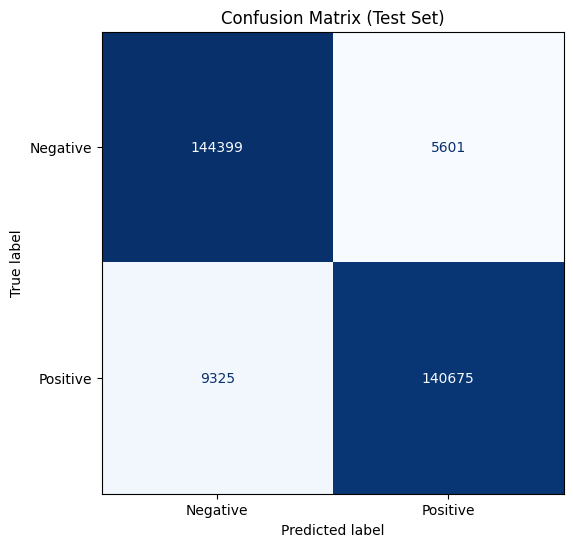

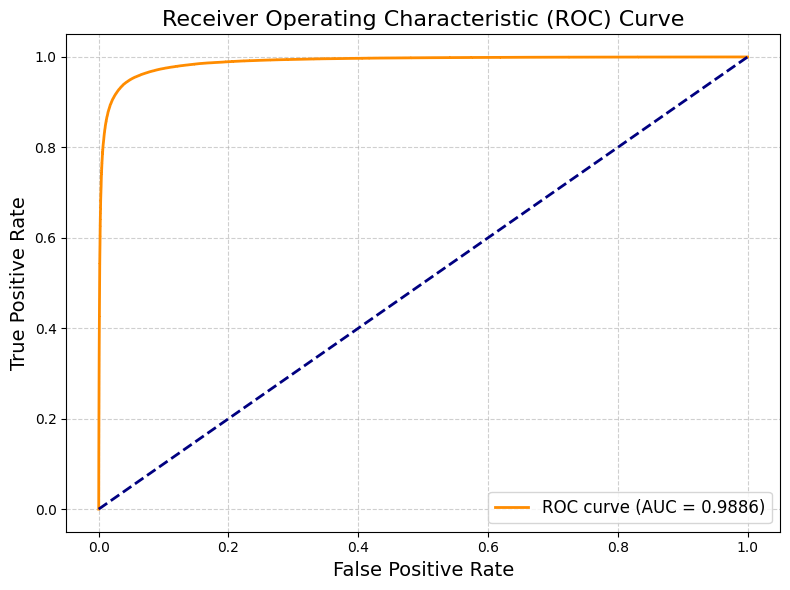

In [31]:
# Cell: Evaluate model on test set and plot performance
from sklearn.metrics import confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay, RocCurveDisplay

# Load best model
model.load_state_dict(torch.load("/kaggle/working/best_bilstm_model.pt"))
model.eval()

all_preds = []
all_probs = []
all_targets = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(CONFIG["DEVICE"])
        labels = batch["label"].to(CONFIG["DEVICE"]).float()
        lengths = batch["length"].to(CONFIG["DEVICE"])
        logits = model(input_ids, lengths).squeeze(1)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).long()
        all_preds.append(preds.cpu().numpy())
        all_probs.append(probs.cpu().numpy())
        all_targets.append(labels.cpu().numpy())

all_preds = np.concatenate(all_preds)
all_probs = np.concatenate(all_probs)
all_targets = np.concatenate(all_targets)

# Test accuracy
test_acc = (all_preds == all_targets).mean()
print(f"Test Accuracy: {test_acc*100:.2f}%")

# Confusion matrix
cm = confusion_matrix(all_targets, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title("Confusion Matrix (Test Set)")
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

# ROC curve and AUC
fpr, tpr, _ = roc_curve(all_targets, all_probs)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=16)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('/kaggle/working/roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()


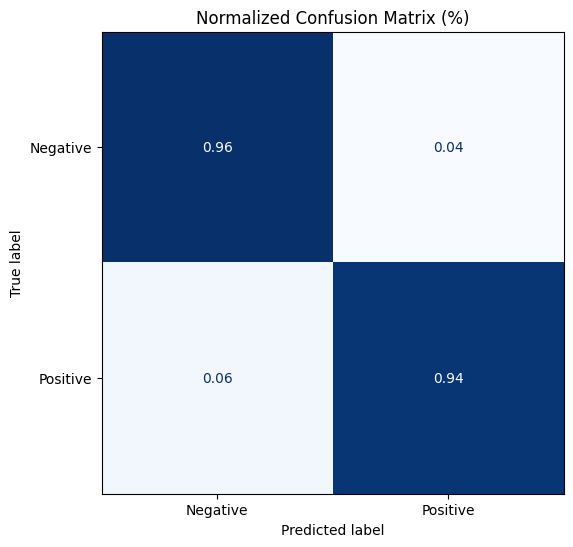

In [32]:
cm = confusion_matrix(all_targets, all_preds, normalize='true')  # row-normalized

# Multiply by 100 for percentage display
cm_percent = np.round(cm * 100, 2)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='.2f')
plt.title("Normalized Confusion Matrix (%)")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.savefig("/kaggle/working/confusion_matrix_normalized.png", dpi=300, bbox_inches='tight')
plt.show()

In [33]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print(f"Test Accuracy: {accuracy_score(all_targets, all_preds)*100:.2f}%")
print(f"Test Precision: {precision_score(all_targets, all_preds):.4f}")
print(f"Test Recall: {recall_score(all_targets, all_preds):.4f}")
print(f"Test F1 Score: {f1_score(all_targets, all_preds):.4f}")
print("\nClassification Report:\n", classification_report(all_targets, all_preds, target_names=["Negative", "Positive"]))

Test Accuracy: 95.02%
Test Precision: 0.9617
Test Recall: 0.9378
Test F1 Score: 0.9496

Classification Report:
               precision    recall  f1-score   support

    Negative       0.94      0.96      0.95    150000
    Positive       0.96      0.94      0.95    150000

    accuracy                           0.95    300000
   macro avg       0.95      0.95      0.95    300000
weighted avg       0.95      0.95      0.95    300000

